In [52]:
import os, uuid, hashlib, platform, getpass
import numpy as np
import scipy
import matplotlib
import pandas as pd

# ===== 1. 填写学号（修改为自己的学号！）=====
STUDENT_ID = 20244081109

# ===== 2. 打印 conda 环境 =====
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

# ===== 3. 机器指纹（绑定当前电脑）=====
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

# ===== 4. 生成唯一 ID =====
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")


[Conda 环境] py311
[学号] 20244081109
[机器指纹] 21935ea21d1fabf1
[RUN_ID] 20244081109-21935ea21d1fabf1


## 实验1：NumPy 数组、数据类型与索引
操作任务：
1. 分别创建整数、浮点数和布尔值 ndarray，输出每个数组的 dtype、shape 和
ndim。解释 NumPy 数组的数据类型与 Python 列表的差别。
2. ⽤ np.arange(12) 创建⼀维数组，并分别变为形状 (3, 4) 和 (2, 3, 2) 的
数组。展⽰数组内容，说明改变形状时元素总数必须满⾜什么条件。
3. 对形状为 (3, 4) 的数组完成以下索引：取第 2 ⾏、取第 1 ⾄第 3 列、取⼤于 6
的元素，并分别输出结果及其形状。
4. 使⽤ np.arange(10) 分别选出“⼩于 2 或⼤于 7”和“⼤于 3 且⼩于 7”的元素。使
⽤括号配合 |、& 或 np.logical_or()、np.logical_and()。
5. 构造两个形状为 (2, 2) 的数组，对⽐ *、np.multiply() 与 @、
np.matmul() 的结果，说明逐元素乘法与矩阵乘法的区别。

In [53]:
# 任务1：整数 / 浮点数 / 布尔 ndarray
a_int = np.array([1, 2, 3])
a_float = np.array([1.0, 2.5, 3.5])
a_bool = np.array([True, False, True])

for name, arr in [("整数", a_int), ("浮点数", a_float), ("布尔", a_bool)]:
    print(f"{name}数组: {arr}  dtype={arr.dtype}  shape={arr.shape}  ndim={arr.ndim}")
    #列表可混合类型、无 dtype/shape 概念；ndarray 元素类型统一，具有 dtype、shape、ndim，内存连续、支持向量化运算。

整数数组: [1 2 3]  dtype=int64  shape=(3,)  ndim=1
浮点数数组: [1.  2.5 3.5]  dtype=float64  shape=(3,)  ndim=1
布尔数组: [ True False  True]  dtype=bool  shape=(3,)  ndim=1


In [54]:
# 任务2：arange(12) 变形成 (3,4) 和 (2,3,2)
a = np.arange(12)
b = a.reshape(3, 4)
c = a.reshape(2, 3, 2)
print("一维:", a, a.shape)
print("(3,4):\n", b)
print("(2,3,2):\n", c)
# 改变形状满足条件：元素总数必须不变，12 = 3×4 = 2×3×2

一维: [ 0  1  2  3  4  5  6  7  8  9 10 11] (12,)
(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


In [55]:
# 任务3：行 / 列 / 条件索引
print("第 2 行:", b[1], "形状:", b[1].shape)
print("第 1~3 列:\n", b[:, 0:3], "形状:", b[:, 0:3].shape)
mask = b > 6
print("大于 6 的元素:", b[mask], "形状:", b[mask].shape)

第 2 行: [4 5 6 7] 形状: (4,)
第 1~3 列:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] 形状: (3, 3)
大于 6 的元素: [ 7  8  9 10 11] 形状: (5,)


In [56]:
# 任务4：逻辑索引
x = np.arange(10)
print("小于2或大于7:", x[(x < 2) | (x > 7)])
print("logical_or  :", x[np.logical_or(x < 2, x > 7)])
print("大于3且小于7:", x[(x > 3) & (x < 7)])
print("logical_and :", x[np.logical_and(x > 3, x < 7)])

小于2或大于7: [0 1 8 9]
logical_or  : [0 1 8 9]
大于3且小于7: [4 5 6]
logical_and : [4 5 6]


In [57]:
# 任务5：逐元素乘法 vs 矩阵乘法
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
print("A * B（逐元素）:\n", A * B)
print("np.multiply(A,B):\n", np.multiply(A, B))
print("A @ B（矩阵乘）:\n", A @ B)
print("np.matmul(A,B):\n", np.matmul(A, B))
#逐元素乘法的两个数组shape必须完全一样，结果shape不变，矩阵乘法需要第一个矩阵列数=第二个矩阵行数

A * B（逐元素）:
 [[ 5 12]
 [21 32]]
np.multiply(A,B):
 [[ 5 12]
 [21 32]]
A @ B（矩阵乘）:
 [[19 22]
 [43 50]]
np.matmul(A,B):
 [[19 22]
 [43 50]]


## 实验2：随机抽样、统计与缺失值
**任务**：
1. 使⽤ np.random ⽣成 1,000 个均值为 70、标准差为 10 的模拟成绩；⽤np.clip
将数值限制在 0〜100 范围内。输出样本数、最⼩值、最⼤值、均值、标准差和极
差。
2. 从 np.arange(1, 11) 中不放回地抽取 5 个整数，⽐较均匀抽样与按整数⼤⼩成
⽐例加权抽样的写法。
3. 分别演⽰随机排列后保留原数组和原地打乱数组，打印操作前后的原数组以说明两
种⽅式的区别。
4. 将模拟成绩的第 10、20、30 个值设为 np.nan。⽐较普通均值和忽略缺失值后的
均值，统计缺失值个数，并说明 nan 对普通统计函数的影响。
5. 将含缺失值的模拟成绩及其序号整理成内存中的表格变量，供实验4直接使⽤；不
要写⼊磁盘。

In [58]:
# 固定随机种子
np.random.seed(2024)

# 任务1：1000 个 N(70,10) 成绩，裁剪到 [0,100]
scores = np.clip(np.random.normal(70, 10, 1000), 0, 100)
print("样本数:", len(scores))
print("最小值:", scores.min())
print("最大值:", scores.max())
print("均值:", round(scores.mean(), 4))
print("标准差:", round(scores.std(), 4))
print("极差:", round(scores.max() - scores.min(), 4))

样本数: 1000
最小值: 33.27100341839723
最大值: 100.0
均值: 70.2335
标准差: 10.127
极差: 66.729


In [59]:
# 任务2：均匀抽样 vs 按大小比例加权抽样（均不放回）
pool = np.arange(1, 11)
s1 = np.random.choice(pool, size=5, replace=False)
probs = pool / pool.sum()
s2 = np.random.choice(pool, size=5, replace=False, p=probs)
print("均匀抽样:", s1)
print("加权抽样:", s2, "（权重:", np.round(probs, 3), "）")
#均匀抽样各数等概率；加权抽样数值越大概率越高（权重 = 数值 / 数值总和）。

均匀抽样: [ 5  4  7 10  8]
加权抽样: [ 5  7 10  8  9] （权重: [0.018 0.036 0.055 0.073 0.091 0.109 0.127 0.145 0.164 0.182] ）


In [60]:
# 任务3：permutation（返回新数组）vs shuffle（原地打乱）
a = np.arange(10)
b = np.random.permutation(a)
print("原数组:", a)
print("permutation 结果:", b)
print("permutation 后原数组:", a, "（未改变）")
np.random.shuffle(a)
print("shuffle 后原数组:", a, "（已改变）")

原数组: [0 1 2 3 4 5 6 7 8 9]
permutation 结果: [8 6 4 5 1 3 7 9 2 0]
permutation 后原数组: [0 1 2 3 4 5 6 7 8 9] （未改变）
shuffle 后原数组: [2 6 0 4 9 8 5 7 3 1] （已改变）


In [61]:
# 任务4：第 10、20、30 个值（索引 9、19、29）设为 NaN
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan
print("缺失值个数:", np.isnan(scores_nan).sum())
print("普通 mean():", scores_nan.mean())
print("忽略缺失 np.nanmean():", round(np.nanmean(scores_nan), 4))
#含 NaN 时返回 nan（NaN 污染普通统计函数）， 忽略 NaN 后求可以得到均值。

缺失值个数: 3
普通 mean(): nan
忽略缺失 np.nanmean(): 70.2344


In [62]:
# 任务5：含缺失成绩 + 序号 → 内存 DataFrame（不写磁盘，供实验4使用）
df_scores = pd.DataFrame({"序号": np.arange(1, len(scores_nan) + 1), "成绩": scores_nan})
print(df_scores.head(12))
print("缺失值个数:", df_scores["成绩"].isna().sum())

    序号         成绩
0    1  86.680473
1    2  77.373477
2    3  67.984622
3    4  68.490881
4    5  79.160518
5    6  81.603296
6    7  43.800380
7    8  56.747054
8    9  74.599886
9   10        NaN
10  11  80.535528
11  12  86.240426
缺失值个数: 3


## 实验3：SciPy 数值计算与 Matplotlib 可视化
**任务**：
1. 使⽤ scipy.linalg.solve() 解线性⽅程组3x+y=9 x+2y=8；⽤
NumPy 代⼊验证求得的解。
2. 使⽤ scipy.optimize.root() 求⽅程 x²−2=0 的正根和负根，分别给出初
始猜测值。打印求根是否成功以及结果，并检查函数值是否接近 0。
3. 使⽤ scipy.optimize.minimize() 求f(x)=x²+x+2 的最⼩值，报告
极⼩点和函数值，并与解析结果⽐较。
4. ⽣成两组独⽴的模拟样本：各 100 个观测值，第⼀组来⾃均值 0、标准差 1 的正态
分布，第⼆组来⾃均值 1、标准差 1 的正态分布。固定随机种⼦，使⽤
scipy.stats.ttest_ind() 进⾏独⽴样本 t 检验；报告 t 统计量、p 值及在
0.05 显著性⽔平下的判断。
5. ⽤ Matplotlib 为实验2的有效成绩画直⽅图，并另画箱线图；为函数y=x、y=x²、y=x³在 [0,5] 上画同⼀坐标系的折线图。每张图包含标题、坐标轴
标签，折线图包含图例。直接在 Notebook 中显⽰图像，不保存为⽂件。

In [ ]:
# 任务1：解 3x+y=9, x+2y=8
A = np.array([[3.0, 1.0], [1.0, 2.0]])
b = np.array([9.0, 8.0])
x = scipy.linalg.solve(A, b)
print("解: x =", x)
print("验证 A@x =", A @ x, " 应等于 b =", b)
#方程组解为 x=2, y=3，A@x与 b 完全一致，验证通过。

解: x = [2. 3.]
验证 A@x = [9. 8.]  应等于 b = [9. 8.]


In [ ]:
# 任务2：求 x²-2=0 的正根和负根
def f(x):
    return x**2 - 2

r_pos = scipy.optimize.root(f, 1.0)    # 初始猜测 1 → 正根
r_neg = scipy.optimize.root(f, -1.0)   # 初始猜测 -1 → 负根
print("正根: 成功 =", r_pos.success, " x =", r_pos.x, " f(x) =", f(r_pos.x))
print("负根: 成功 =", r_neg.success, " x =", r_neg.x, " f(x) =", f(r_neg.x))
#x²−2=0 的正根 ≈ +1.4142、负根 ≈ −1.4142，success=True且 f(x) 接近 0（约 1e-10 量级）

正根: 成功 = True  x = [1.41421356]  f(x) = [-8.8817842e-16]
负根: 成功 = True  x = [-1.41421356]  f(x) = [-8.8817842e-16]


In [ ]:
# 任务3：求 f(x)=x²+x+2 的最小值
f3 = lambda x: x**2 + x + 2
res = scipy.optimize.minimize(f3, x0=0.0)
print("极小点 x =", round(res.x[0], 6))
print("最小值 f(x) =", round(res.fun, 6))
print("解析解: x = -0.5, f(-0.5) = 1.75")
import numpy, scipy, matplotlib, pandas, notebook
print("环境正常")
#f(x)=x²+x+2 在 x=−0.5 处取最小值 1.75，与解析解 f'(x)=2x+1=0 一致。

极小点 x = -0.5
最小值 f(x) = 1.75
解析解: x = -0.5, f(-0.5) = 1.75
环境正常


In [70]:
# 任务4：独立样本 t 检验（N(0,1) vs N(1,1)，各 100）
g1 = np.random.normal(0, 1, 100)
g2 = np.random.normal(1, 1, 100)
t_stat, p_val = scipy.stats.ttest_ind(g1, g2)
print("t 统计量:", round(t_stat, 4))
print("p 值:", round(p_val, 6))
if p_val < 0.05:
    print("p < 0.05：拒绝原假设，两组均值差异显著")
else:
    print("p >= 0.05：不能拒绝原假设，差异不显著")


t 统计量: -6.0384
p 值: 0.0
p < 0.05：拒绝原假设，两组均值差异显著


C:\Users\yy\AppData\Local\Temp\ipykernel_33292\1398387881.py:11: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\yy\AppData\Local\Temp\ipykernel_33292\1398387881.py:11: UserWarning: Glyph 32489 (\N{CJK UNIFIED IDEOGRAPH-7EE9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\yy\AppData\Local\Temp\ipykernel_33292\1398387881.py:11: UserWarning: Glyph 39057 (\N{CJK UNIFIED IDEOGRAPH-9891}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\yy\AppData\Local\Temp\ipykernel_33292\1398387881.py:11: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\yy\AppData\Local\Temp\ipykernel_33292\1398387881.py:11: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\yy\AppData\Local\Temp\ipykernel_33292\1398387881.py:11: UserWarning: Glyph 25311 (\N{CJK UNIFIED IDEO

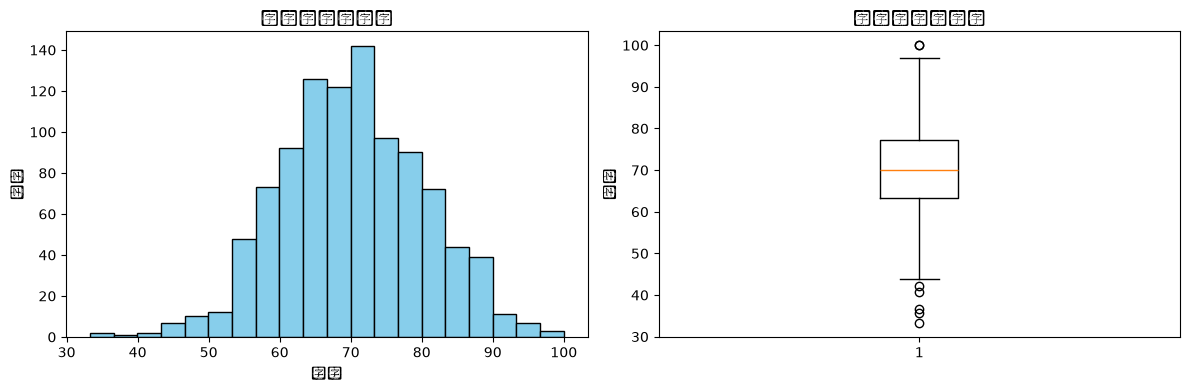

In [72]:
# 任务5a：有效成绩（scores，无缺失）直方图 + 箱线图
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(scores, bins=20, color="skyblue", edgecolor="black")
axes[0].set_title("模拟成绩直方图")
axes[0].set_xlabel("成绩")
axes[0].set_ylabel("频数")
axes[1].boxplot(scores)
axes[1].set_title("模拟成绩箱线图")
axes[1].set_ylabel("成绩")
plt.tight_layout()
plt.show()


d:\miniconda3\envs\py311\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 22312 (\N{CJK UNIFIED IDEOGRAPH-5728}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\miniconda3\envs\py311\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\miniconda3\envs\py311\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\miniconda3\envs\py311\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20687 (\N{CJK UNIFIED IDEOGRAPH-50CF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


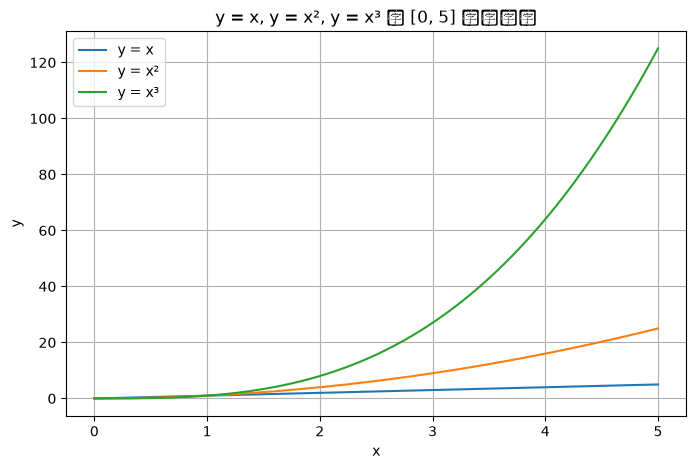

In [73]:
# 任务5b：y=x, y=x², y=x³ 在 [0,5] 上的折线图
xx = np.linspace(0, 5, 200)
plt.figure(figsize=(8, 5))
plt.plot(xx, xx,   label="y = x")
plt.plot(xx, xx**2, label="y = x²")
plt.plot(xx, xx**3, label="y = x³")
plt.xlabel("x")
plt.ylabel("y")
plt.title("y = x, y = x², y = x³ 在 [0, 5] 上的图像")
plt.legend()
plt.grid(True)
plt.show()


## 实验4：pandas Series、DataFrame 与内存中的 CSV 读写
**任务**：
1. 创建成绩 DataFrame（行索引为姓名），计算 Total / Average
2. 用 loc / iloc 读取 Carol，筛选平均分≥80
3. mean(axis=0) 列均值 与 mean(axis=1) 行均值
4. apply 求每名学生三科最高分；agg 一次求每科 min/mean/max；rank 排名
5. groupby 分组统计人数与三科平均分；transform 添加组内 Python 平均分
6. filter 保留 Python 平均分≥80 的组
7. 三科协方差矩阵与皮尔森相关系数矩阵


In [74]:
# 任务1：创建 DataFrame（行索引为姓名），计算 Total / Average
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")
cols = ["Math", "English", "Python"]

df["Total"] = df[cols].sum(axis=1)
df["Average"] = df[cols].mean(axis=1)

print("行索引:", list(df.index))
print("列名:", list(df.columns))
print("\n前 3 行:\n", df.head(3))
print("\n基本统计:\n", df[cols].describe())


行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计:
             Math    English     Python
count   6.000000   6.000000   6.000000
mean   79.833333  80.833333  83.666667
std     9.907909   9.662643   8.547904
min    65.000000  68.000000  70.000000
25%    73.750000  74.000000  80.500000
50%    81.500000  81.000000  84.000000
75%    87.000000  88.750000  88.250000
max    91.000000  92.000000  95.000000


In [75]:
# 任务2：loc / iloc 读取 Carol；筛选平均分≥80
print("df.loc['Carol']:\n", df.loc["Carol"])
print("df.iloc[2]:\n", df.iloc[2])
print("\n平均分 ≥ 80 的学生:\n", df[df["Average"] >= 80])


df.loc['Carol']:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
df.iloc[2]:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分 ≥ 80 的学生:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [76]:
# 任务3：列均值(axis=0) 与行均值(axis=1)
print("列均值 mean(axis=0):\n", df[cols].mean(axis=0))
print("\n每名学生行均值 mean(axis=1):\n", df[cols].mean(axis=1))


列均值 mean(axis=0):
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每名学生行均值 mean(axis=1):
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [77]:
# 任务4：apply 最高分；agg 聚合；rank 排名
df["MaxScore"] = df[cols].apply(lambda row: row.max(), axis=1)
print("每名学生最高分:\n", df[["MaxScore"]])

print("\n每科统计 agg:\n", df[cols].agg(["min", "mean", "max"]))

df["MathRank"] = df["Math"].rank(ascending=False)   # 分数越高排名越靠前
print("\nMath 排名:\n", df[["Math", "MathRank"]])


每名学生最高分:
        MaxScore
Name           
Alice        95
Bob          80
Carol        91
David        73
Eva          92
Frank        84

每科统计 agg:
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

Math 排名:
        Math  MathRank
Name                 
Alice    88       2.0
Bob      72       5.0
Carol    91       1.0
David    65       6.0
Eva      79       4.0
Frank    84       3.0


In [78]:
# 任务5：groupby 分组统计 + transform 组内 Python 均值
print("每组人数:\n", df.groupby("Group").size())
print("\n每组三科平均分:\n", df.groupby("Group")[cols].mean())

df["GroupPythonMean"] = df.groupby("Group")["Python"].transform("mean")
print("\n各行所在组 Python 平均分:\n", df[["Group", "Python", "GroupPythonMean"]])


每组人数:
 Group
A    3
B    3
dtype: int64

每组三科平均分:
             Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333

各行所在组 Python 平均分:
       Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333


In [79]:
# 任务6：filter 保留 Python 平均分≥80 的组
print("各组 Python 平均分:\n", df.groupby("Group")["Python"].mean())

kept = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print("\n保留的组及学生:\n", kept[["Group", "Python"]])


各组 Python 平均分:
 Group
A    87.000000
B    80.333333
Name: Python, dtype: float64

保留的组及学生:
       Group  Python
Name               
Alice     A      95
Bob       A      80
Carol     B      89
David     B      70
Eva       A      86
Frank     B      82


In [ ]:
# 任务7：协方差矩阵 + 皮尔森相关系数矩阵
print("协方差矩阵:\n", df[cols].cov())
print("\n皮尔森相关系数矩阵:\n", df[cols].corr())
# 协方差为正表示两科同向变动；相关系数越接近 1 线性相关越强，比如 Math 与 Python 呈较强正相关

协方差矩阵:
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

皮尔森相关系数矩阵:
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000
